# Stage 3 of 3 - Modeling and Evaluation: Predicting Indian Train Speed

*Part of the SWYNEX Final Data Science Project: prepare -> explore -> model -> conclude.*

**Builds on:** Stage 1 (data preparation) and Stage 2 (EDA) on the DataMeet Indian Railways data.

**Problem:** predict a train's average scheduled speed (km/h) from information known
*before* the timetable is fixed: distance, train type, zone, route size, class
availability and departure hour. From a predicted speed we can estimate a journey time
for a proposed service.

**What Stage 2 taught me, and how it shapes this model**

| Stage 2 finding | Modeling decision |
|---|---|
| speed = distance / duration, so duration **leaks** the target | Duration and everything derived from it are excluded |
| Distance is right-skewed | Use `log(distance)` |
| Train type explains far more than zone | Compare feature sets and check with ablations |
| Missing zone is informative | Keep `Unknown` as its own category |
| A train and its return train are near-identical rows | Use **grouped** cross-validation, not a random split |

**Plan:** baseline -> simple linear models -> tree models -> honest evaluation
(cross-validation + held-out test + bootstrap) -> error analysis -> limitations.

In [1]:
from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy import stats
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, KFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

warnings.filterwarnings("ignore")
SEED = 42
import os
# Run from the project root whether launched from the root, scripts/ or notebooks/
if Path.cwd().name in ("scripts", "notebooks"):
    os.chdir(Path.cwd().parent)

FIG, REP, MOD = Path("reports/figures/model"), Path("reports/model"), Path("models")
for d in (FIG, REP, MOD):
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#4C72B0", "#C44E52", "#55A868", "#DD8452", "#8172B2", "#8C8C8C"


def save(name):
    plt.tight_layout()
    plt.savefig(FIG / name, dpi=150)
    plt.show()

## 1. Load data and build the modeling table
Rows excluded: the 3 implausible-speed rows flagged in Stage 1 and the trains with no valid distance.

In [2]:
trains = pd.read_csv("data/processed/trains_clean.csv", keep_default_na=False, na_values=[""],
                     dtype={"train_id": str, "train_no": str, "return_train_no": str})
df = trains[~trains["speed_suspect"] & trains["avg_speed_kmph"].notna()].copy()
print(f"Trains in clean file: {len(trains):,} -> usable for modeling: {len(df):,}")

# Features
df["log_distance"] = np.log(df["distance_km"])
df["dep_hour"] = df["departure_min"] // 60
df["has_return"] = df["return_train_no"].notna().astype(int)
df["has_ac"] = (df["first_ac"] | df["second_ac"] | df["third_ac"]).astype(int)
for c in ("sleeper", "chair_car"):
    df[c] = df[c].astype(int)

# Rare train types (<30 trains) are grouped: too few rows to learn from reliably.
counts = df["train_type"].value_counts()
rare = counts[counts < 30].index
df["type_grp"] = df["train_type"].where(~df["train_type"].isin(rare), "Other").astype(str)
df["zone"] = df["zone"].astype(str)
print("Rare types grouped into 'Other':", sorted(map(str, rare)))

NUM = ["log_distance", "route_points", "dep_hour", "has_return", "has_ac", "sleeper", "chair_car", "n_classes"]
CAT = ["type_grp", "zone"]
TARGET = "avg_speed_kmph"
X, y = df[NUM + CAT], df[TARGET].to_numpy()
print(f"Features: {len(NUM)} numeric + {len(CAT)} categorical | target: {TARGET}")

Trains in clean file: 5,193 -> usable for modeling: 5,163
Rare types grouped into 'Other': ['DEMU (diesel multiple unit)', 'Del', 'Klkt', 'Mail', 'Toy train']
Features: 8 numeric + 2 categorical | target: avg_speed_kmph


### Leakage audit: what is deliberately NOT used

| Column | Why excluded |
|---|---|
| `duration_min` | speed = distance / duration, so it reconstructs the target |
| `arrival_min`, `arrival_time`, `days_en_route`, `is_overnight` | arrival = departure + duration: duration in disguise |
| `avg_speed_kmph`, `speed_suspect`, `geo_ratio` | the target or built from it / from distance checks |
| `route_km_geo` | near-duplicate of distance (Spearman 0.99) |
| `train_id`, `train_no`, station codes and names | identifiers; a model would memorise them |
| `origin_state`, `dest_state`, `is_interstate` | missing for ~80% of trains |

I later *prove* the leakage point by training a deliberately leaky model.

## 2. Cross-validation groups
A train and its return train share distance, type and zone, so they are near-duplicates.
Slip coaches share a base number with their parent train. If one twin is in training and
the other in testing, the score is inflated. I put each such family into one **group**
and split by group.

In [3]:
pair_key = np.where(df["return_train_no"].notna(),
                    np.minimum(df["train_no"], df["return_train_no"].fillna("99999")),
                    df["train_no"])
groups = pd.factorize(pair_key)[0]
print(f"{len(df):,} trains fall into {len(set(groups)):,} independent groups")

5,163 trains fall into 3,102 independent groups


## 3. Models
All models share one pipeline: one-hot encode categories, pass numbers through.

| Model | Purpose |
|---|---|
| **Dummy (median)** | The floor. Any useful model must beat it |
| **Linear: log(distance) only** | Simplest meaningful baseline |
| **Linear: + train type** | Tests Stage 2's "type matters" insight |
| **Linear: all features** | Strong linear reference |
| **Hist Gradient Boosting** | Non-linear, captures interactions |
| **Random Forest** | Non-linear, robust, few settings to tune |

In [4]:
def make_pipe(model, cats):
    enc = ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=False), cats)]
        if cats else [], remainder="passthrough")
    return Pipeline([("prep", enc), ("model", model)])


SPECS = {
    "Dummy (median)": (lambda: DummyRegressor(strategy="median"), ["log_distance"], []),
    "Linear: distance": (lambda: LinearRegression(), ["log_distance"], []),
    "Linear: distance + type": (lambda: LinearRegression(), ["log_distance", "type_grp"], ["type_grp"]),
    "Linear: all features": (lambda: LinearRegression(), NUM + CAT, CAT),
    "Hist Gradient Boosting": (lambda: HistGradientBoostingRegressor(random_state=SEED), NUM + CAT, CAT),
    "Random Forest": (lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=3,
                                                    random_state=SEED, n_jobs=-1), NUM + CAT, CAT),
}
SCORING = {"r2": "r2", "mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}


def cv_scores(name, cv, grp=None, extra_cols=()):
    factory, cols, cats = SPECS[name]
    cols = list(cols) + list(extra_cols)
    res = cross_validate(make_pipe(factory(), cats), df[cols], y, cv=cv, groups=grp,
                         scoring=SCORING, n_jobs=1)
    return {"r2": res["test_r2"], "mae": -res["test_mae"], "rmse": -res["test_rmse"]}

## 4. Evaluate with grouped 5-fold cross-validation
**Metrics**
- **MAE** (km/h): the average miss, easiest to explain
- **RMSE** (km/h): punishes big misses more
- **R-squared**: share of speed variation explained (0 = no better than the average)

In [5]:
gkf = GroupKFold(n_splits=5)
rows = []
for name in SPECS:
    s = cv_scores(name, gkf, groups)
    rows.append({"model": name, "R2": s["r2"].mean(), "R2_std": s["r2"].std(),
                 "MAE": s["mae"].mean(), "MAE_std": s["mae"].std(),
                 "RMSE": s["rmse"].mean(), "RMSE_std": s["rmse"].std()})
cv_table = pd.DataFrame(rows).set_index("model")
cv_table.round(3).to_csv(REP / "cv_model_comparison.csv")
print(cv_table.round(3))

                            R2  R2_std     MAE  MAE_std    RMSE  RMSE_std
model                                                                    
Dummy (median)          -0.011   0.003  10.470    0.100  12.915     0.144
Linear: distance         0.467   0.012   7.253    0.224   9.377     0.185
Linear: distance + type  0.710   0.014   5.202    0.133   6.914     0.169
Linear: all features     0.746   0.013   4.868    0.117   6.467     0.174
Hist Gradient Boosting   0.800   0.010   4.186    0.089   5.740     0.149
Random Forest            0.805   0.010   4.064    0.103   5.666     0.139


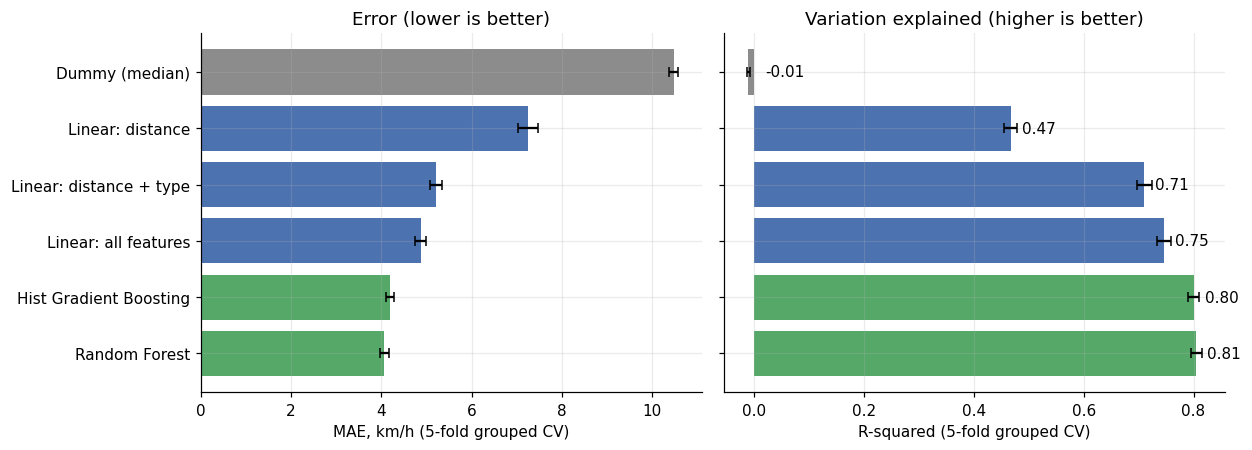

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2), sharey=True)
order = cv_table.index[::-1]
colors = [GREY if "Dummy" in m else BLUE if "Linear" in m else GREEN for m in order]
ax[0].barh(order, cv_table.loc[order, "MAE"], xerr=cv_table.loc[order, "MAE_std"], color=colors, capsize=3)
ax[0].set(title="Error (lower is better)", xlabel="MAE, km/h (5-fold grouped CV)")
ax[1].barh(order, cv_table.loc[order, "R2"], xerr=cv_table.loc[order, "R2_std"], color=colors, capsize=3)
ax[1].set(title="Variation explained (higher is better)", xlabel="R-squared (5-fold grouped CV)")
for i, m in enumerate(order):
    ax[1].text(max(cv_table.loc[m, "R2"], 0) + 0.02, i, f"{cv_table.loc[m, 'R2']:.2f}", va="center")
save("01_model_comparison.png")

**Reading the results:** the median-guess baseline explains nothing (R2 ~ 0). Distance
alone explains under half of the variation; adding train type jumps it to about 71% (Stage 2's
insight, now measured). The two tree models do best. Random Forest and Hist Gradient Boosting
are within noise of each other (compare the error bars), so I pick by lowest CV MAE.

## 5. Check: did a random split inflate the score?
I compare **random** 5-fold CV with **grouped** 5-fold CV, plus a deliberately **leaky**
model that is given `duration_min`.

                        random_split_R2  grouped_split_R2  inflation
model                                                               
Linear: all features              0.748             0.746      0.002
Hist Gradient Boosting            0.830             0.800      0.030
Random Forest                     0.846             0.805      0.041

LEAKY model (HGB + duration_min), grouped CV: R2 = 0.968


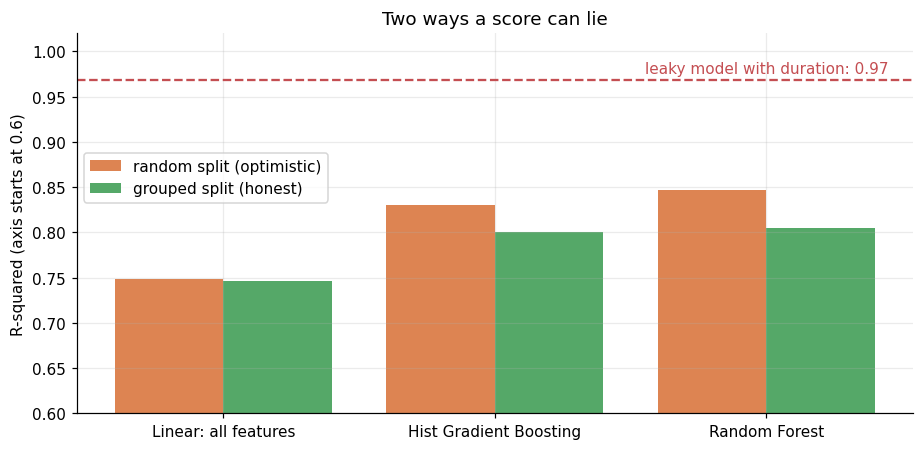

In [7]:
rkf = KFold(n_splits=5, shuffle=True, random_state=SEED)
cmp_rows = []
for name in ["Linear: all features", "Hist Gradient Boosting", "Random Forest"]:
    r = cv_scores(name, rkf)["r2"].mean()
    g = cv_scores(name, gkf, groups)["r2"].mean()
    cmp_rows.append({"model": name, "random_split_R2": r, "grouped_split_R2": g, "inflation": r - g})
leak = cv_scores("Hist Gradient Boosting", gkf, groups, extra_cols=["duration_min"])["r2"].mean()
split_cmp = pd.DataFrame(cmp_rows).set_index("model")
split_cmp.round(3).to_csv(REP / "random_vs_grouped_cv.csv")
print(split_cmp.round(3))
print(f"\nLEAKY model (HGB + duration_min), grouped CV: R2 = {leak:.3f}")

fig, ax = plt.subplots(figsize=(8.5, 4.2))
x = np.arange(len(split_cmp))
ax.bar(x - 0.2, split_cmp["random_split_R2"], 0.4, label="random split (optimistic)", color=ORANGE)
ax.bar(x + 0.2, split_cmp["grouped_split_R2"], 0.4, label="grouped split (honest)", color=GREEN)
ax.axhline(leak, color=RED, ls="--")
ax.text(len(split_cmp) - 0.55, leak + 0.008, f"leaky model with duration: {leak:.2f}", color=RED, ha="right")
ax.set_xticks(x, split_cmp.index)
ax.set(ylim=(0.6, 1.02), ylabel="R-squared (axis starts at 0.6)", title="Two ways a score can lie")
ax.legend(loc="center left", bbox_to_anchor=(0.0, 0.62))
save("02_leakage_checks.png")

**Two ways a score can lie.** (1) A random split lets a train and its return twin land on
both sides, which flatters the tree models (they can memorise near-duplicates), while the
linear model barely changes. (2) Giving the model `duration_min` pushes R2 above 0.96:
that model looks brilliant and is useless, because duration is unknown when planning a
new service. The honest number is the grouped one.

## 6. Final test: a held-out set the models never saw
I pick the best tree model by CV MAE, keep 20% of the *groups* aside, train on the other
80%, and report once. Models are compared against the baseline on the same test set.

In [8]:
best_name = cv_table.loc[["Hist Gradient Boosting", "Random Forest"], "MAE"].idxmin()
print("Best model by grouped-CV MAE:", best_name)

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(splitter.split(X, y, groups))
assert not set(groups[train_idx]) & set(groups[test_idx]), "group leakage between train and test"
X_tr, X_te, y_tr, y_te = X.iloc[train_idx], X.iloc[test_idx], y[train_idx], y[test_idx]
print(f"Train: {len(X_tr):,} trains | Test: {len(X_te):,} trains (no group appears in both)")


def fit_eval(name):
    factory, cols, cats = SPECS[name]
    p = make_pipe(factory(), cats).fit(X_tr[cols], y_tr)
    return p, p.predict(X_te[cols])


results, preds = [], {}
for name in ["Dummy (median)", "Linear: distance + type", "Linear: all features", best_name]:
    p, pr = fit_eval(name)
    preds[name] = pr
    results.append({"model": name, "R2": r2_score(y_te, pr), "MAE": mean_absolute_error(y_te, pr),
                    "RMSE": np.sqrt(mean_squared_error(y_te, pr))})
test_table = pd.DataFrame(results).set_index("model")
test_table.round(3).to_csv(REP / "test_set_results.csv")
print(test_table.round(3))

final_pipe, final_pred = fit_eval(best_name)
resid = y_te - final_pred

# Bootstrap 95% confidence intervals (resampling the test trains)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(y_te), len(y_te))
    boot.append((r2_score(y_te[i], final_pred[i]), mean_absolute_error(y_te[i], final_pred[i])))
boot = np.array(boot)
ci_r2, ci_mae = np.percentile(boot[:, 0], [2.5, 97.5]), np.percentile(boot[:, 1], [2.5, 97.5])
print(f"\n{best_name} on test set:")
print(f"  R2  = {r2_score(y_te, final_pred):.3f}  (95% CI {ci_r2[0]:.3f} to {ci_r2[1]:.3f})")
print(f"  MAE = {mean_absolute_error(y_te, final_pred):.2f} km/h  (95% CI {ci_mae[0]:.2f} to {ci_mae[1]:.2f})")

Best model by grouped-CV MAE: Random Forest
Train: 4,106 trains | Test: 1,057 trains (no group appears in both)


                            R2     MAE    RMSE
model                                         
Dummy (median)          -0.028  10.660  13.260
Linear: distance + type  0.706   5.182   7.089
Linear: all features     0.744   4.870   6.618
Random Forest            0.818   3.896   5.574



Random Forest on test set:
  R2  = 0.818  (95% CI 0.792 to 0.843)
  MAE = 3.90 km/h  (95% CI 3.65 to 4.14)


## 7. How good are the predictions, visually?

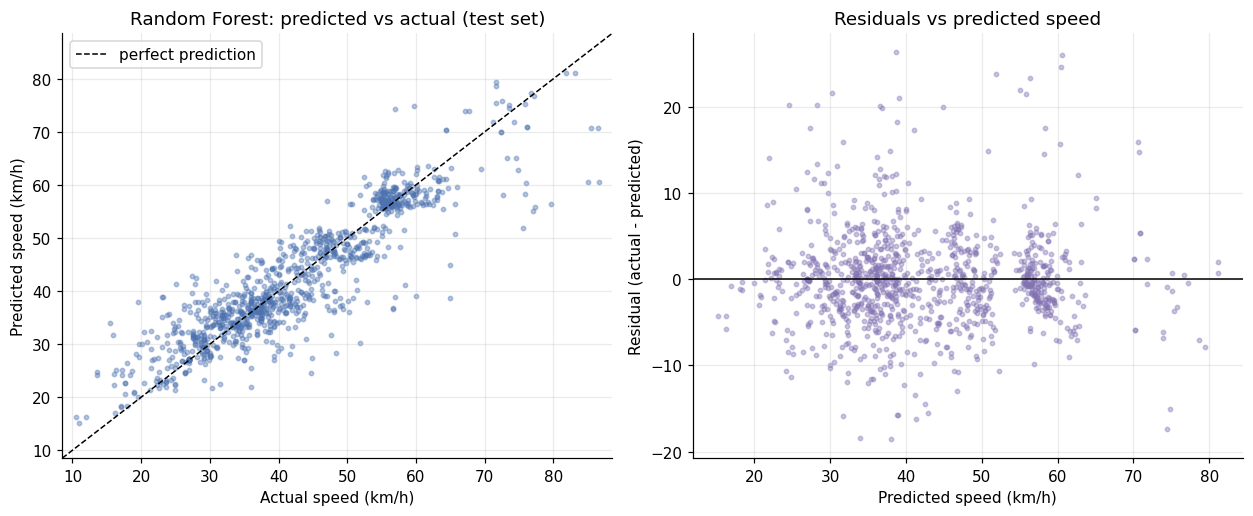

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.8))
ax[0].scatter(y_te, final_pred, s=8, alpha=0.4, color=BLUE)
lim = [min(y_te.min(), final_pred.min()) - 2, max(y_te.max(), final_pred.max()) + 2]
ax[0].plot(lim, lim, "k--", lw=1, label="perfect prediction")
ax[0].set(xlabel="Actual speed (km/h)", ylabel="Predicted speed (km/h)", xlim=lim, ylim=lim,
          title=f"{best_name}: predicted vs actual (test set)")
ax[0].legend()
ax[1].scatter(final_pred, resid, s=8, alpha=0.4, color=PURPLE)
ax[1].axhline(0, color="k", lw=1)
ax[1].set(xlabel="Predicted speed (km/h)", ylabel="Residual (actual - predicted)",
          title="Residuals vs predicted speed")
save("03_predicted_vs_actual.png")

The points hug the diagonal, but at the fast end they sit **below** it: the model
under-predicts the fastest trains, a common shrinking-toward-the-average effect of tree
models. I measure it instead of assuming it is small.

In [10]:
bias = pd.DataFrame({"actual": y_te, "resid": resid})
bias["actual_band"] = pd.cut(bias["actual"], [0, 30, 50, 65, 200], labels=["<30", "30-50", "50-65", ">65"])
bias_tbl = bias.groupby("actual_band", observed=True).agg(n=("resid", "size"), mean_residual=("resid", "mean"),
                                                         MAE=("resid", lambda r: r.abs().mean())).round(2)
bias_tbl.to_csv(REP / "bias_by_actual_speed.csv")
print("Mean residual (actual - predicted) by actual speed band:")
print(bias_tbl)

Mean residual (actual - predicted) by actual speed band:
               n  mean_residual   MAE
actual_band                          
<30          197          -3.90  4.47
30-50        548           0.24  3.47
50-65        274           1.20  3.60
>65           38           7.14  9.15


## 8. What does the model rely on? (permutation importance)
For each feature I shuffle its values on the **test set** and measure how much R2 drops.
A bigger drop means the model depends on that feature more.

     feature  r2_drop   std
    type_grp    0.781 0.042
log_distance    0.403 0.030
   n_classes    0.218 0.017
        zone    0.083 0.006
route_points    0.073 0.005
   chair_car    0.010 0.002
    dep_hour    0.003 0.002
  has_return    0.002 0.001
      has_ac    0.001 0.001
     sleeper    0.001 0.000


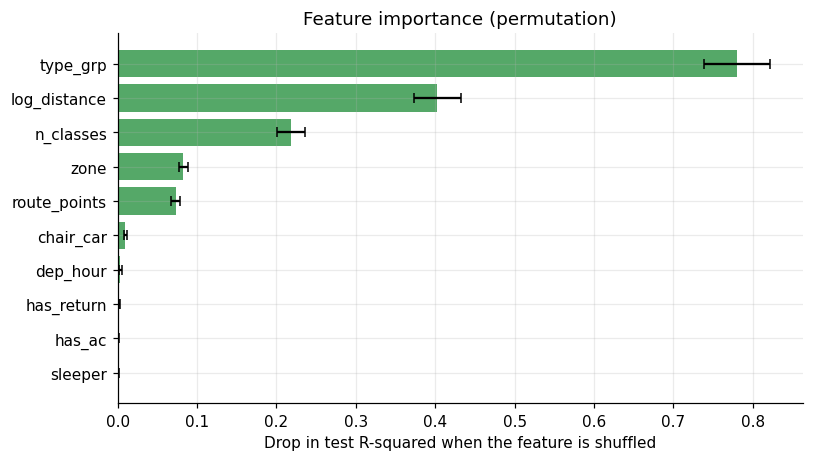

In [11]:
imp = permutation_importance(final_pipe, X_te, y_te, n_repeats=20, random_state=SEED, scoring="r2")
imp_df = pd.DataFrame({"feature": X_te.columns, "r2_drop": imp.importances_mean,
                       "std": imp.importances_std}).sort_values("r2_drop")
imp_df.round(4).to_csv(REP / "permutation_importance.csv", index=False)
print(imp_df.sort_values("r2_drop", ascending=False).round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.barh(imp_df["feature"], imp_df["r2_drop"], xerr=imp_df["std"], color=GREEN, capsize=3)
ax.set(xlabel="Drop in test R-squared when the feature is shuffled",
       title="Feature importance (permutation)")
save("04_feature_importance.png")

### Ablation: remove one feature group and retrain
This is a second, independent check of Stage 2's "type matters more than zone".

In [12]:
abl = []
base_cv = cv_table.loc[best_name, "R2"]
CLASS_FEATS = ["n_classes", "has_ac", "sleeper", "chair_car"]
variants = [("full model", []), ("without train type", ["type_grp"]), ("without zone", ["zone"]),
            ("without type and zone", ["type_grp", "zone"]),
            ("without class features", CLASS_FEATS), ("without route_points", ["route_points"])]
for label, drop in variants:
    cats = [c for c in CAT if c not in drop]
    cols = [c for c in NUM if c not in drop] + cats
    model = SPECS[best_name][0]()
    r = cross_validate(make_pipe(model, cats), df[cols], y, cv=gkf, groups=groups, scoring="r2")["test_score"]
    abl.append({"variant": label, "R2": r.mean(), "change_vs_full": r.mean() - base_cv})
abl_df = pd.DataFrame(abl).set_index("variant")
abl_df.round(3).to_csv(REP / "ablation_results.csv")
print(abl_df.round(3))

                           R2  change_vs_full
variant                                      
full model              0.805           0.000
without train type      0.724          -0.081
without zone            0.769          -0.036
without type and zone   0.677          -0.128
without class features  0.802          -0.003
without route_points    0.796          -0.009


**Two tools, two different questions.**
- *Permutation importance* asks "does the trained model **use** this feature?"
- *Ablation (retraining without it)* asks "does this feature add **new information**?"

They can disagree. `n_classes` ranks third in permutation importance, yet removing all four
class features costs only about 0.003 R2. The reason: class availability is strongly tied to
train type and distance, so the model can rebuild the same signal from them. Shuffling
`n_classes` breaks combinations the model learned to rely on, which exaggerates its apparent
importance. This confirms the Stage 2 note that class features add little beyond type and
distance, and shows why permutation scores of correlated features should not be read as
unique contributions (they also do not add up to 1).

## 9. Error analysis: where does the model struggle?

MAE by train type (n>=10):
                                  n   MAE
train_type                              
Hyd                             20  1.81
Superfast                      171  2.52
MEMU (electric multiple unit)   50  3.43
Express                        253  3.72
Rajdhani                        10  3.91
Passenger                      485  4.24
Jan Shatabdi                    18  4.56
Duronto                         10  6.90
Garib Rath                      10  9.18
Other                           12  9.72 

MAE by distance band:
              n   MAE
dist_band           
<100       267  3.92
100-300    300  4.43
300-600    183  3.56
600-1000   113  3.95
>1000      194  3.34 

Unknown-zone trains vs others:
        size  mean
unk              
False  1011  3.87
True     46  4.39


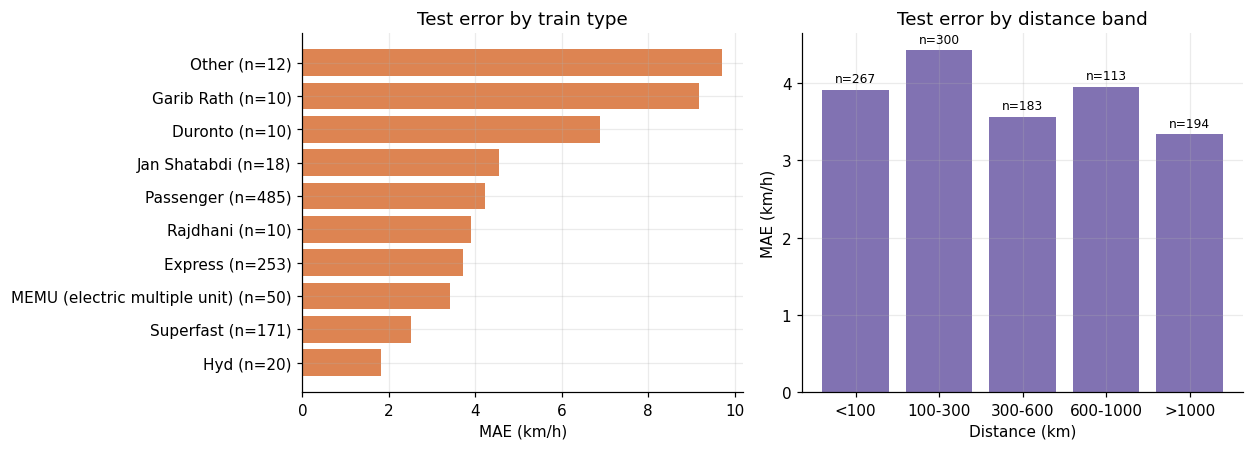


Largest errors (saved for manual review):
train_id                                    name   train_type zone  distance_km  actual  predicted  abs_error
   56641               Verna Mangalore Passenger    Passenger   SR        454.0    64.9       38.6       26.3
   12052        MADGAON - DADAR Jan Shatabdi Exp Jan Shatabdi   KR        765.0    86.6       60.6       26.0
   12051        DADAR - MADGAON Jan Shatabdi Exp Jan Shatabdi   KR        765.0    85.0       60.5       24.5
   52110                Matheran Neral Passenger    Toy train   CR        126.0    75.6       51.8       23.8
   52102                Matheran Neral Passenger    Toy train   CR        126.0    79.6       56.3       23.3
   12612 H Nizamuddin-Chennai Garib Rath Express   Garib Rath   SR       2176.0    77.0       55.0       22.0


In [13]:
err = pd.DataFrame({"train_type": df.iloc[test_idx]["type_grp"].values,
                    "distance_km": df.iloc[test_idx]["distance_km"].values,
                    "zone": df.iloc[test_idx]["zone"].values,
                    "actual": y_te, "pred": final_pred})
err["abs_err"] = (err["actual"] - err["pred"]).abs()
err["dist_band"] = pd.cut(err["distance_km"], [0, 100, 300, 600, 1000, 4500],
                          labels=["<100", "100-300", "300-600", "600-1000", ">1000"])
by_type = err.groupby("train_type").agg(n=("abs_err", "size"), MAE=("abs_err", "mean")).query("n >= 10").sort_values("MAE")
by_band = err.groupby("dist_band", observed=True).agg(n=("abs_err", "size"), MAE=("abs_err", "mean"))
by_zone_unknown = err.assign(unk=err["zone"] == "Unknown").groupby("unk")["abs_err"].agg(["size", "mean"])
print("MAE by train type (n>=10):\n", by_type.round(2), "\n")
print("MAE by distance band:\n", by_band.round(2), "\n")
print("Unknown-zone trains vs others:\n", by_zone_unknown.round(2))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.2))
ax[0].barh([f"{t} (n={n})" for t, n in zip(by_type.index, by_type["n"])], by_type["MAE"], color=ORANGE)
ax[0].set(title="Test error by train type", xlabel="MAE (km/h)")
ax[1].bar(by_band.index.astype(str), by_band["MAE"], color=PURPLE)
for i, (m, n) in enumerate(zip(by_band["MAE"], by_band["n"])):
    ax[1].text(i, m + 0.1, f"n={n}", ha="center", fontsize=8)
ax[1].set(title="Test error by distance band", xlabel="Distance (km)", ylabel="MAE (km/h)")
save("05_error_analysis.png")

worst = (df.iloc[test_idx][["train_id", "name", "train_type", "zone", "distance_km"]]
         .assign(actual=y_te, predicted=final_pred.round(1), abs_error=np.abs(resid).round(1))
         .sort_values("abs_error", ascending=False).head(15))
worst.to_csv(REP / "largest_prediction_errors.csv", index=False)
print("\nLargest errors (saved for manual review):")
print(worst.head(6).to_string(index=False))

## 10. Can the model's mistakes point to bad data?
The largest errors included records that looked wrong (a toy train listed at 126 km running
at 75 km/h). I test this properly. Using **out-of-fold** predictions for every train (each
train is predicted by a model that never saw its group), I compare errors against the
geometry ratio from Stage 1: *route length drawn on the map / stated distance*. A low ratio
means the stated distance is much longer than the mapped route.

**Hypothesis:** trains with a low ratio have less trustworthy records, so the model should
miss them by more.

               n   MAE
ratio_band            
<0.8         136  7.99
0.8-0.9      273  4.33
0.9-1.0     4034  3.88
>=1.0        705  4.18

Trains with ratio < 0.8: 136 (2.6% of all)
Their share of the 100 largest errors: 20%  (enrichment x7.6)
MAE: ratio<0.8 = 7.99 km/h vs others = 3.95 km/h (Mann-Whitney p = 4.5e-15)
Share of the 100 largest errors caught by the FIRST-PASS Stage 1 rule (ratio>1.2 or <0.33): 5% (base rate 2.3%)

Upper tail check - ratio > 1.2: 92 trains, MAE 4.61 vs 3.94 for the middle range (Mann-Whitney p = 0.34) -> not flagged

Review candidates (ratio<0.8 and error>15 km/h): 22 trains -> data_quality_review_candidates.csv


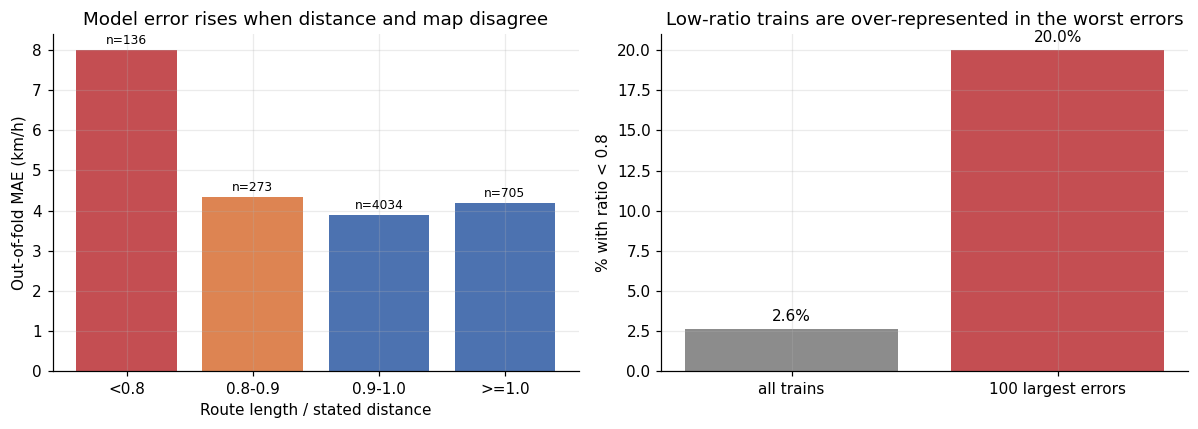

In [14]:
oof = cross_val_predict(make_pipe(SPECS[best_name][0](), CAT), X, y, cv=gkf, groups=groups)
oofdf = df[["train_id", "name", "train_type", "zone", "distance_km", "route_km_geo", "geo_ratio"]].copy()
oofdf["actual"], oofdf["predicted"] = y, oof
oofdf["abs_err"] = np.abs(y - oof)
oofdf = oofdf.dropna(subset=["geo_ratio"])
oofdf["ratio_band"] = pd.cut(oofdf["geo_ratio"], [0, 0.8, 0.9, 1.0, 5],
                             labels=["<0.8", "0.8-0.9", "0.9-1.0", ">=1.0"], right=False)
band = oofdf.groupby("ratio_band", observed=True).agg(n=("abs_err", "size"), MAE=("abs_err", "mean"))
print(band.round(2))

low = oofdf["geo_ratio"] < 0.8
top100 = oofdf.nlargest(100, "abs_err")
share_all, share_top = low.mean(), (top100["geo_ratio"] < 0.8).mean()
_, p_mw = stats.mannwhitneyu(oofdf.loc[low, "abs_err"], oofdf.loc[~low, "abs_err"])
print(f"\nTrains with ratio < 0.8: {low.sum()} ({share_all:.1%} of all)")
print(f"Their share of the 100 largest errors: {share_top:.0%}  (enrichment x{share_top / share_all:.1f})")
print(f"MAE: ratio<0.8 = {oofdf.loc[low, 'abs_err'].mean():.2f} km/h vs others = {oofdf.loc[~low, 'abs_err'].mean():.2f} km/h "
      f"(Mann-Whitney p = {p_mw:.1e})")
print(f"Share of the 100 largest errors caught by the FIRST-PASS Stage 1 rule (ratio>1.2 or <0.33): "
      f"{((top100['geo_ratio'] > 1.2) | (top100['geo_ratio'] < 0.33)).mean():.0%} (base rate 2.3%)")

high = oofdf["geo_ratio"] > 1.2
mid = ~low & ~high
_, p_hi = stats.mannwhitneyu(oofdf.loc[high, "abs_err"], oofdf.loc[mid, "abs_err"])
print(f"\nUpper tail check - ratio > 1.2: {high.sum()} trains, MAE {oofdf.loc[high, 'abs_err'].mean():.2f} "
      f"vs {oofdf.loc[mid, 'abs_err'].mean():.2f} for the middle range (Mann-Whitney p = {p_hi:.2f}) -> not flagged")

review = oofdf[low & (oofdf["abs_err"] > 15)].sort_values("abs_err", ascending=False)
review[["train_id", "name", "train_type", "distance_km", "route_km_geo", "geo_ratio", "actual", "predicted", "abs_err"]
       ].round(2).to_csv(REP / "data_quality_review_candidates.csv", index=False)
print(f"\nReview candidates (ratio<0.8 and error>15 km/h): {len(review)} trains -> data_quality_review_candidates.csv")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(band.index.astype(str), band["MAE"], color=[RED, ORANGE, BLUE, BLUE])
for i, (m, n) in enumerate(zip(band["MAE"], band["n"])):
    ax[0].text(i, m + 0.15, f"n={n}", ha="center", fontsize=8)
ax[0].set(xlabel="Route length / stated distance", ylabel="Out-of-fold MAE (km/h)",
          title="Model error rises when distance and map disagree")
ax[1].bar(["all trains", "100 largest errors"], [share_all * 100, share_top * 100], color=[GREY, RED])
for i, v in enumerate([share_all * 100, share_top * 100]):
    ax[1].text(i, v + 0.5, f"{v:.1f}%", ha="center")
ax[1].set(ylabel="% with ratio < 0.8", title="Low-ratio trains are over-represented in the worst errors")
save("07_errors_vs_geometry.png")

**What this shows (and does not).** Trains whose stated distance is much longer than the
mapped route are only a few percent of the data, yet they make up a far larger share of the
worst errors, and their error is about double. So large errors are a useful **signal of
unreliable records**. Two cautions: (1) a low ratio can also come from a simplified route
line, not a wrong distance, so these are *review candidates*, not proven mistakes;
(2) the errors are not one-directional, so this is not a simple bias the model could correct.
It also shows that my **first-pass Stage 1 flag threshold (ratio < 0.33) was too loose**.
This finding fed back into the pipeline: the final Stage 1 rule flags ratio < 0.8 (see
`01_data_preparation`). I also checked the upper tail (ratio > 1.2, 92 trains): its error
(MAE 4.6 vs 3.94 km/h for the middle range, p = 0.34) is not significantly worse, so it is not flagged.
The flag is a data-quality marker only and is never a model feature.

## 11. From speed to a number a planner can use: journey time
Predicted journey time = distance / predicted speed. The true duration is used **only here,
to score** the result, never as a model input.

Baseline (median speed)    median abs error =   77.2 min | median % error =  23.6% | within 15%: 34%
Random Forest              median abs error =   26.9 min | median % error =   6.6% | within 15%: 80%


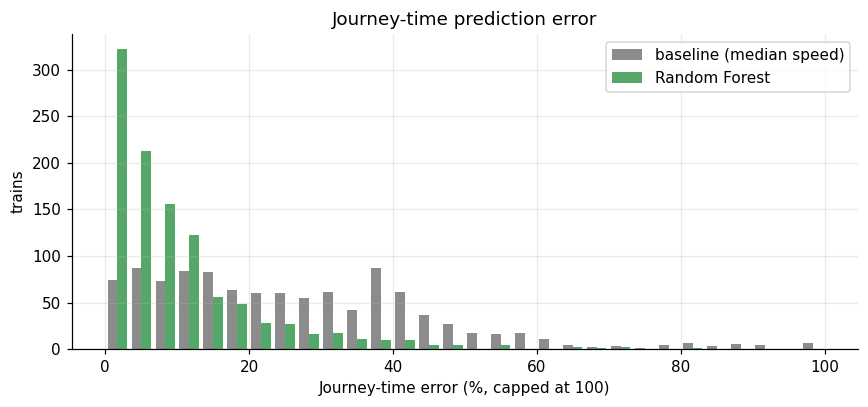

In [15]:
te = df.iloc[test_idx].copy()
te["pred_speed"] = final_pred
te["pred_minutes"] = te["distance_km"] / te["pred_speed"] * 60
base_speed = float(np.median(y_tr))
te["base_minutes"] = te["distance_km"] / base_speed * 60
te = te[te["duration_min"].notna()]
for label, col in [("Baseline (median speed)", "base_minutes"), (best_name, "pred_minutes")]:
    ae = (te[col] - te["duration_min"]).abs()
    pe = ae / te["duration_min"] * 100
    print(f"{label:26s} median abs error = {ae.median():6.1f} min | median % error = {pe.median():5.1f}% "
          f"| within 15%: {(pe <= 15).mean():.0%}")

journey = pd.DataFrame({
    "baseline_median_pct_err": [((te["base_minutes"] - te["duration_min"]).abs() / te["duration_min"] * 100).median()],
    "model_median_pct_err": [((te["pred_minutes"] - te["duration_min"]).abs() / te["duration_min"] * 100).median()],
    "model_within_15pct": [(((te["pred_minutes"] - te["duration_min"]).abs() / te["duration_min"]) <= 0.15).mean()],
    "model_median_abs_err_min": [(te["pred_minutes"] - te["duration_min"]).abs().median()],
}).round(3)
journey.to_csv(REP / "journey_time_error.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.8))
pe_m = ((te["pred_minutes"] - te["duration_min"]).abs() / te["duration_min"] * 100).clip(upper=100)
pe_b = ((te["base_minutes"] - te["duration_min"]).abs() / te["duration_min"] * 100).clip(upper=100)
ax.hist([pe_b, pe_m], bins=30, label=["baseline (median speed)", best_name], color=[GREY, GREEN])
ax.set(xlabel="Journey-time error (%, capped at 100)", ylabel="trains", title="Journey-time prediction error")
ax.legend()
save("06_journey_time_error.png")

## 12. Demo: predictions for real unseen trains

In [16]:
demo = df.iloc[test_idx].sample(8, random_state=7)[["train_id", "name", "train_type", "zone", "distance_km"]].copy()
demo["actual_kmph"] = y_te[[list(df.iloc[test_idx].index).index(i) for i in demo.index]]
demo["predicted_kmph"] = final_pipe.predict(X.loc[demo.index]).round(1)
demo["error_kmph"] = (demo["predicted_kmph"] - demo["actual_kmph"]).round(1)
demo["name"] = demo["name"].str.slice(0, 32)
print(demo.to_string(index=False))

train_id                             name                    train_type    zone  distance_km  actual_kmph  predicted_kmph  error_kmph
   11064       SALEM - CHENNAI EGMORE Exp                       Express      CR        353.0         45.1            41.9        -3.2
   19115 MUMBAI BANDRA - BHUJ Sayaji Naga                       Express      WR        839.0         49.8            50.6         0.8
   52453             Kalka Shimla Express                     Passenger      NR         96.0         18.9            20.9         2.0
   12827           Howrah Purulia Express                     Superfast     SER        323.0         58.7            58.6        -0.1
   11065 MUMBAI LTT - DARBHANGA Pawan Exp                       Express      CR       1880.0         50.7            50.9         0.2
   31921                  SDAH GEDE LOCAL MEMU (electric multiple unit) Unknown        116.0         42.7            43.1         0.4
   59320          Bhopal Ujjain Passenger                     

## 13. Save the final model
The exported model is retrained on **all** usable trains (the test split was only for honest evaluation).

In [17]:
deploy = make_pipe(SPECS[best_name][0](), CAT).fit(X, y)
joblib.dump(deploy, MOD / "speed_model.joblib", compress=3)
size_mb = (MOD / "speed_model.joblib").stat().st_size / 1e6
print(f"Saved models/speed_model.joblib ({size_mb:.1f} MB)")

summary = {
    "usable_trains": len(df), "groups": int(len(set(groups))),
    "best_model": best_name,
    "cv_R2": round(float(cv_table.loc[best_name, 'R2']), 3),
    "cv_MAE": round(float(cv_table.loc[best_name, 'MAE']), 2),
    "baseline_cv_R2": round(float(cv_table.loc['Dummy (median)', 'R2']), 3),
    "test_R2": round(float(r2_score(y_te, final_pred)), 3),
    "test_MAE": round(float(mean_absolute_error(y_te, final_pred)), 2),
    "leaky_R2": round(float(leak), 3),
}
print(summary)

Saved models/speed_model.joblib (11.0 MB)
{'usable_trains': 5163, 'groups': 3102, 'best_model': 'Random Forest', 'cv_R2': 0.805, 'cv_MAE': 4.06, 'baseline_cv_R2': -0.011, 'test_R2': 0.818, 'test_MAE': 3.9, 'leaky_R2': 0.968}
